# 03 · Product quantization: save memory by compressing

**The question.** IVF made search faster but kept every vector as 384 floats — 1,536 bytes each.
What if memory, not speed, is the wall?

**The claim.** Split each vector into sub-vectors, replace each sub-vector by the index of its
nearest codeword in a small learned codebook, and store those indices — one byte each. A
1,536-byte vector becomes 48 bytes, distances are computed straight from the bytes, and ten to a
hundred times more vectors fit in the same RAM. The price, again, is recall: distances are now
approximate.

**By the end** you will have built product quantization (PQ) from scratch, seen exactly how much
memory each byte budget saves and how much recall it costs, and combined it with IVF (IVFPQ) to
pull both levers at once.

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from src import visualisation as vis
from src.artifacts import save_figure, save_json
from src.config import get_settings
from src.datasets.vectors import load_dataset
from src.evaluation.speed import machine_info, pinned_threads

S = get_settings()
K, SEED, THREADS = S.eval.k, S.seed, S.bench.threads
NB_START = time.perf_counter()
MACHINE = machine_info(THREADS)
pd.set_option("display.width", 140, "display.max_colwidth", 90)


def show(fig, slug: str) -> None:
    """Save the figure as outputs/figures/<slug>.png, then display it once."""
    save_figure(fig, slug)
    plt.close(fig)
    display(fig)


print(MACHINE)

{'cpu': 'Intel(R) Xeon(R) Platinum 8370C CPU @ 2.80GHz', 'logical_cpus': 2, 'threads': 1, 'python': '3.14.2', 'numpy': '2.5.4', 'faiss': '1.15.1', 'hnswlib': '0.8.0'}


## How it works

`src/indexes/pq.py`, following Jégou, Douze & Schmid (2011):

1. **Split** every 384-d vector into `n_subvectors` pieces (48 pieces of 8 dims, say).
2. **Learn a codebook per piece:** k-means with 256 centroids on that slice of the training data.
3. **Encode:** each piece becomes the index (0–255) of its nearest codeword — one `uint8`.
   48 pieces → 48 bytes per vector instead of 1,536.
4. **Search with ADC** (asymmetric distance computation): keep the query exact, build a table
   `T[j, c]` = distance from the query's piece `j` to codeword `c` (48 × 256 numbers), then the
   distance to any stored vector is a sum of 48 table lookups. The database is never decoded.

That is the same move as `quantization_101`'s scalar quantization of model weights — replace
precise numbers by a few bits — except the grid is learned, per sub-vector, by k-means.

In [2]:
from src.indexes.pq import PQIndex

news = load_dataset("news")
pq_cfg = S.pq
demo = PQIndex(n_subvectors=pq_cfg.n_subvectors, nbits=pq_cfg.nbits, train_size=pq_cfg.train_size,
               kmeans_max_iter=pq_cfg.kmeans_max_iter, seed=SEED)
demo.train(news.base)
demo.add(news.base[:5])
codes = demo.codes[0]
recon = demo.reconstruct()[0]
err = float(((recon - news.base[0]) ** 2).sum())
print(f"vector 0: {news.d} float32 = {news.d * 4} bytes")
print(f"PQ code : {codes.size} x uint8 = {codes.nbytes} bytes -> {codes[:12].tolist()} ...")
print(f"squared reconstruction error {err:.3f} (the vector's squared norm is 1.0)")

vector 0: 384 float32 = 1536 bytes
PQ code : 48 x uint8 = 48 bytes -> [103, 210, 224, 135, 42, 74, 139, 136, 160, 115, 255, 111] ...
squared reconstruction error 0.243 (the vector's squared norm is 1.0)


## The byte budget, swept

Five code sizes, from 8 to 96 bytes per vector, each trained on 20,000 vectors and scored on the
1,000 held-out queries. Memory is the analytic index size: codes plus the codebooks (which cost
the same 393 KB whatever N is, so they matter only for small databases).

In [3]:
from src.evaluation.memory import exact_bytes, ivf_flat_bytes
from src.evaluation.speed import timed_build
from src.evaluation.triangle import expand_params, sweep, to_frame

rows, kept_indexes = [], {}
with pinned_threads(THREADS):
    for m in pq_cfg.n_subvectors_sweep:
        index = PQIndex(n_subvectors=m, nbits=pq_cfg.nbits, train_size=pq_cfg.train_size,
                        kmeans_max_iter=pq_cfg.kmeans_max_iter, seed=SEED)
        build_s = timed_build(index, news.base)
        rows += sweep(index, None, [], news.queries, news.gt_ids, K, engine="scratch", dataset="news",
                      build_params={"n_subvectors": m, "nbits": pq_cfg.nbits}, build_s=build_s,
                      seed=SEED, threads=THREADS)
        if m in (min(pq_cfg.n_subvectors_sweep), pq_cfg.n_subvectors):
            kept_indexes[m] = index
pq_sweep = expand_params(to_frame(rows))

memory_rows = pd.DataFrame(
    [{"label": "Exact (float32)", "bytes_per_vector": exact_bytes(news.n, news.d) / news.n, "recall": 1.0},
     {"label": f"IVF-Flat (nlist={S.ivf.nlist})", "bytes_per_vector": ivf_flat_bytes(news.n, news.d, S.ivf.nlist) / news.n,
      "recall": np.nan}]
    + [{"label": f"PQ {int(r.n_subvectors)} B code", "bytes_per_vector": r.bytes_per_vector, "recall": r.recall}
       for r in pq_sweep.itertuples()]
)
memory_rows["compression_vs_exact"] = memory_rows["bytes_per_vector"].iloc[0] / memory_rows["bytes_per_vector"]
display(memory_rows.round(3))

,label,bytes_per_vector,recall,compression_vs_exact
0,Exact (float32),1536.000,1.000,1.000
1,IVF-Flat (nlist=256),1551.864,NaN,0.990
2,PQ 8 B code,15.864,0.225,96.821
3,PQ 16 B code,23.864,0.405,64.364
4,PQ 32 B code,39.864,0.606,38.531
5,PQ 48 B code,55.864,0.682,27.495
6,PQ 96 B code,103.864,0.827,14.789


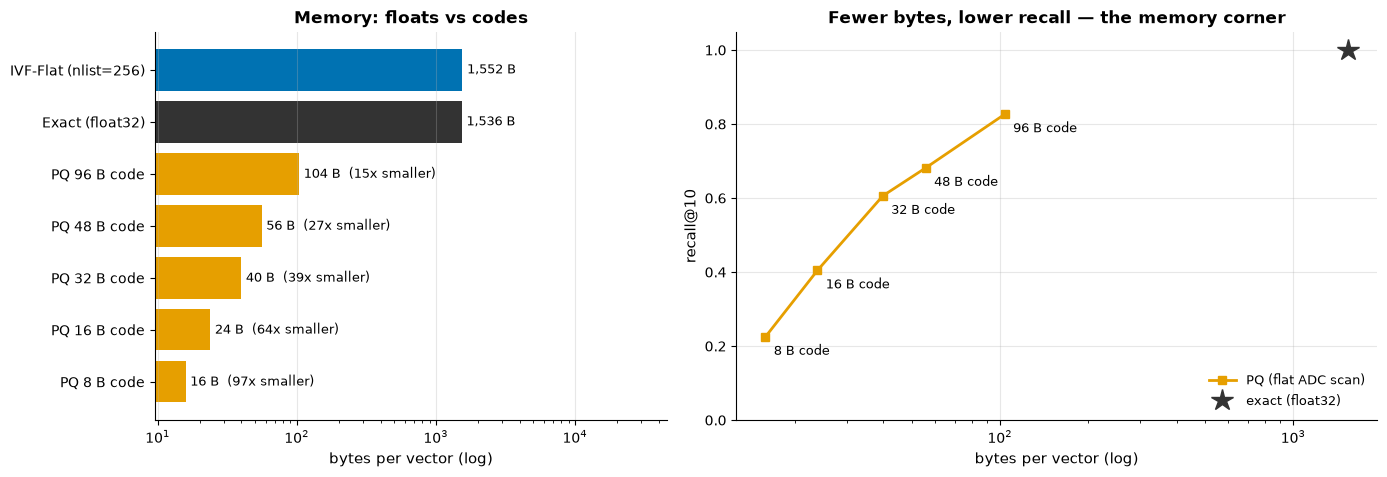

PosixPath('/workspaces/vector_search_101/outputs/results/03_pq_memory_vs_recall.json')

In [4]:
fig = vis.plot_pq_memory(memory_rows.dropna(subset=["bytes_per_vector"]), K)
show(fig, "03_pq_memory_vs_recall")
save_json("03_pq_memory_vs_recall", {
    "dataset": "news", "n": news.n, "d": news.d, "k": K, "nbits": pq_cfg.nbits,
    "rows": memory_rows, "sweep": pq_sweep[["n_subvectors", "recall", "nbytes", "bytes_per_vector", "build_s"]],
})

Every halving of the code costs recall, and the curve bends: the first bytes buy the most.
Even the generous 96-byte code (16x smaller than float32) does not get recall to 1 — PQ distances
are never exact. To see why, compare them with the true distances for one query.

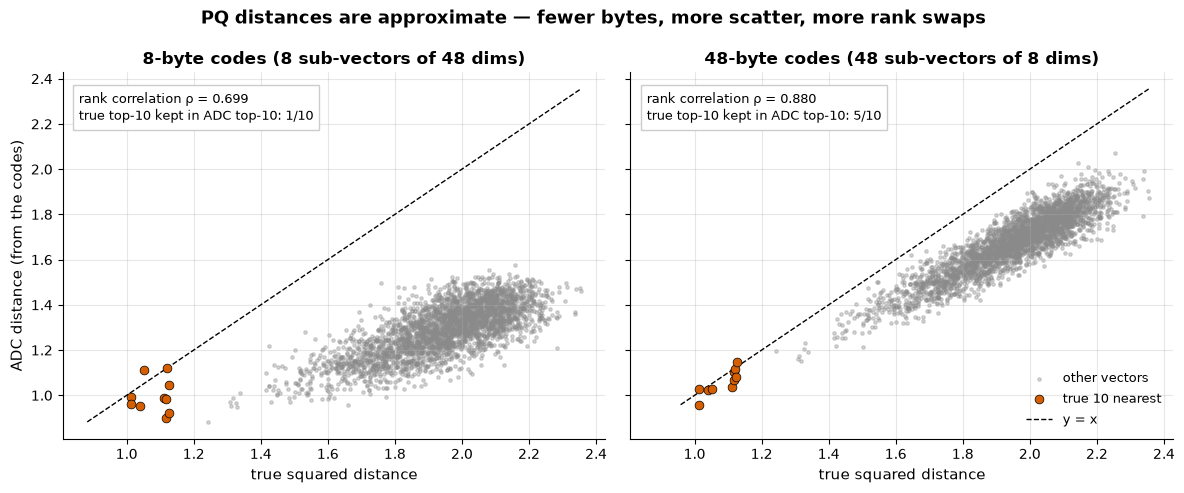

[{'n_subvectors': 8,
  'spearman_all_vectors': 0.6985012781928048,
  'true_top10_in_adc_top10': 1},
 {'n_subvectors': 48,
  'spearman_all_vectors': 0.8800708650839749,
  'true_top10_in_adc_top10': 5}]

In [5]:
from scipy.stats import spearmanr

from src.metrics.distance import sq_l2

qi = 0
q = news.queries[qi : qi + 1]
true_d = sq_l2(q, news.base)[0]
true_top = np.argsort(true_d)[:K]
rng = np.random.default_rng(SEED)
others = rng.choice(np.setdiff1d(np.arange(news.n), true_top), size=3000, replace=False)
show_ids = np.concatenate([others, true_top])
panels, distortion = [], []
for m, index in sorted(kept_indexes.items()):
    adc = index.pq.adc(index.pq.distance_tables(q)[0], index.codes)
    rho = float(spearmanr(true_d, adc).statistic)
    kept = len(set(np.argsort(adc)[:K]) & set(true_top))
    panels.append({"true": true_d[show_ids], "approx": adc[show_ids], "is_top": np.isin(show_ids, true_top),
                   "spearman": rho, "kept": kept,
                   "title": f"{m}-byte codes ({m} sub-vectors of {news.d // m} dims)"})
    distortion.append({"n_subvectors": m, "spearman_all_vectors": rho, "true_top10_in_adc_top10": kept})
fig = vis.plot_adc_distortion(panels)
show(fig, "03_adc_distortion")
save_json("03_adc_distortion", {"dataset": "news", "query_index": qi, "panels": distortion})
distortion

Each grey dot is a stored vector: its true distance against the distance PQ computes from its
code. With 8-byte codes the cloud is wide, so near the top of the ranking — where the 10 true
neighbours (orange) sit — vectors swap places and some neighbours fall out of the top 10. With
48-byte codes the cloud tightens around the diagonal and fewer swaps happen. That is the recall
cost of compression, made visible.

## Both levers: IVFPQ

PQ alone still scores every code (it saves memory, not comparisons). IVF alone skips
comparisons but keeps the floats. Large production indexes combine them: IVF's inverted lists,
holding PQ codes of each vector's **residual** — its offset from its centroid, which is smaller
and easier to quantize than the vector itself (`src/indexes/ivfpq.py`).

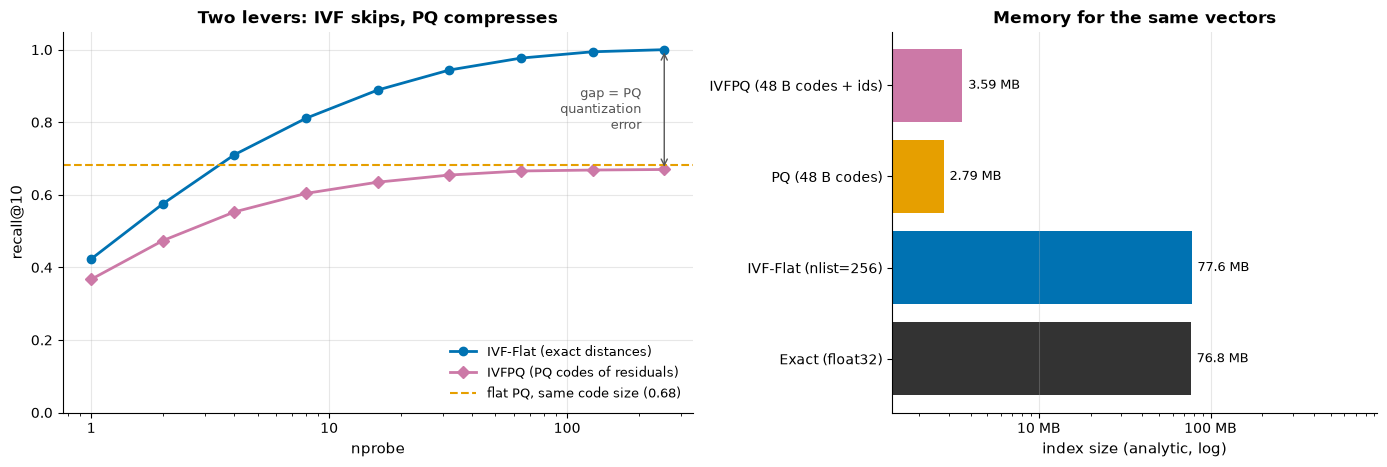

IVFPQ plateau (nprobe=256): 0.670 | flat PQ with the same 48-byte code: 0.682


,nprobe,ivf_recall,ivfpq_recall,ivfpq_work_speedup
0,1,0.423,0.367,102.3
1,2,0.575,0.474,70.3
2,4,0.711,0.553,43.7
3,8,0.811,0.604,25.3
4,16,0.889,0.635,14.0
5,32,0.944,0.654,7.4
6,64,0.977,0.666,3.9
7,128,0.994,0.668,2.0
8,256,1.000,0.670,1.0


In [6]:
from src.indexes.ivf import IVFIndex
from src.indexes.ivfpq import IVFPQIndex

ivfpq_cfg, ivf_cfg = S.ivfpq, S.ivf
with pinned_threads(THREADS):
    ivf = IVFIndex(nlist=ivfpq_cfg.nlist, train_points_per_centroid=ivf_cfg.train_points_per_centroid,
                   kmeans_max_iter=ivf_cfg.kmeans_max_iter, seed=SEED)
    ivf_build = timed_build(ivf, news.base)
    ivf_rows = sweep(ivf, "nprobe", ivfpq_cfg.nprobe_sweep, news.queries, news.gt_ids, K, engine="scratch",
                     dataset="news", build_params={"nlist": ivfpq_cfg.nlist}, build_s=ivf_build,
                     seed=SEED, threads=THREADS)
    ivfpq = IVFPQIndex(nlist=ivfpq_cfg.nlist, n_subvectors=ivfpq_cfg.n_subvectors, nbits=pq_cfg.nbits,
                       train_points_per_centroid=ivf_cfg.train_points_per_centroid,
                       pq_train_size=pq_cfg.train_size, kmeans_max_iter=ivf_cfg.kmeans_max_iter, seed=SEED)
    ivfpq_build = timed_build(ivfpq, news.base)
    ivfpq_rows = sweep(ivfpq, "nprobe", ivfpq_cfg.nprobe_sweep, news.queries, news.gt_ids, K, engine="scratch",
                       dataset="news", build_params={"nlist": ivfpq_cfg.nlist, "n_subvectors": ivfpq_cfg.n_subvectors},
                       build_s=ivfpq_build, seed=SEED, threads=THREADS)
ivf_df, ivfpq_df = expand_params(to_frame(ivf_rows)), expand_params(to_frame(ivfpq_rows))
pq_same = float(pq_sweep.loc[pq_sweep["n_subvectors"] == ivfpq_cfg.n_subvectors, "recall"].iloc[0])
memory = {
    "Exact (float32)": exact_bytes(news.n, news.d),
    f"IVF-Flat (nlist={ivfpq_cfg.nlist})": ivf.nbytes,
    f"PQ ({ivfpq_cfg.n_subvectors} B codes)": kept_indexes[ivfpq_cfg.n_subvectors].nbytes,
    f"IVFPQ ({ivfpq_cfg.n_subvectors} B codes + ids)": ivfpq.nbytes,
}
fig = vis.plot_ivfpq(ivf_df, ivfpq_df, pq_same, memory, K)
show(fig, "03_ivfpq_two_levers")
cols = ["nprobe", "recall", "work", "work_speedup", "nbytes", "build_s"]
save_json("03_ivfpq_two_levers", {"dataset": "news", "k": K, "ivf": ivf_df[cols], "ivfpq": ivfpq_df[cols],
                                  "flat_pq_recall_same_code": pq_same, "memory_bytes": memory})
print(f"IVFPQ plateau (nprobe={ivfpq_cfg.nprobe_sweep[-1]}): {ivfpq_df['recall'].iloc[-1]:.3f} | "
      f"flat PQ with the same {ivfpq_cfg.n_subvectors}-byte code: {pq_same:.3f}")
display(pd.DataFrame({"nprobe": ivf_df["nprobe"], "ivf_recall": ivf_df["recall"].round(3),
                      "ivfpq_recall": ivfpq_df["recall"].round(3),
                      "ivfpq_work_speedup": ivfpq_df["work_speedup"].round(1)}))

IVFPQ follows IVF's curve while few lists are probed, then flattens at PQ's ceiling: once
the right lists are scanned, the remaining misses are rank swaps caused by approximate
distances, and probing more lists cannot fix those. The plateau lands close to flat PQ with the
same 48-byte code (printed above): encoding residuals instead of raw vectors helps in theory,
because residuals are smaller, but on these embeddings it does not change the ceiling much.
Memory is the other way round: IVFPQ costs about what PQ costs — 48 bytes of code plus an 8-byte
id per vector — a small fraction of either float index.

## Checked against faiss

The same configurations in faiss (`IndexPQ`, `IndexIVFPQ`), scored on the same queries:

In [7]:
from src.evaluation.speed import evaluate
from src.reference.compare import FaissIVFPQ, FaissPQ

checks = []
with pinned_threads(THREADS):
    ref_pq = FaissPQ(n_subvectors=pq_cfg.n_subvectors, nbits=pq_cfg.nbits)
    ref_pq.train(news.base[: pq_cfg.train_size])
    ref_pq.add(news.base)
    checks.append({"index": f"PQ {pq_cfg.n_subvectors} B", "scratch_recall": pq_same,
                   "faiss_recall": evaluate(ref_pq, news.queries, news.gt_ids, K)["recall"],
                   "scratch_bytes": kept_indexes[pq_cfg.n_subvectors].nbytes, "faiss_bytes": ref_pq.nbytes})
    ref = FaissIVFPQ(nlist=ivfpq_cfg.nlist, n_subvectors=ivfpq_cfg.n_subvectors, nbits=pq_cfg.nbits, seed=SEED)
    ref.train(news.base[: pq_cfg.train_size])
    ref.add(news.base)
    for nprobe in (4, 16, 64):
        ref.nprobe = nprobe
        ivfpq.nprobe = nprobe
        checks.append({"index": f"IVFPQ nprobe={nprobe}", "scratch_recall": evaluate(ivfpq, news.queries, news.gt_ids, K)["recall"],
                       "faiss_recall": evaluate(ref, news.queries, news.gt_ids, K)["recall"],
                       "scratch_bytes": ivfpq.nbytes, "faiss_bytes": ref.nbytes})
checks = pd.DataFrame(checks)
checks["recall_gap"] = (checks["scratch_recall"] - checks["faiss_recall"]).abs()
save_json("03_vs_faiss", checks)
display(checks.round(3))

,index,scratch_recall,faiss_recall,scratch_bytes,faiss_bytes,recall_gap
0,PQ 48 B,0.682,0.687,2793216,2793302,0.005
1,IVFPQ nprobe=4,0.553,0.555,3586432,3588660,0.002
2,IVFPQ nprobe=16,0.635,0.636,3586432,3588660,0.001
3,IVFPQ nprobe=64,0.666,0.664,3586432,3588660,0.002


In [8]:
pq48 = pq_sweep.loc[pq_sweep["n_subvectors"] == pq_cfg.n_subvectors].iloc[0]
pq8 = pq_sweep.loc[pq_sweep["n_subvectors"] == min(pq_cfg.n_subvectors_sweep)].iloc[0]
top_ivfpq = ivfpq_df.iloc[-1]
summary = {
    "pq48_bytes_per_vector": float(pq48["bytes_per_vector"]),
    "pq48_compression": float(news.d * 4 / pq48["bytes_per_vector"]),
    "pq48_recall": float(pq48["recall"]),
    "pq8_compression": float(news.d * 4 / pq8["bytes_per_vector"]),
    "pq8_recall": float(pq8["recall"]),
    "ivfpq_plateau_recall": float(top_ivfpq["recall"]),
    "ivfpq_bytes": int(ivfpq.nbytes), "exact_bytes": int(exact_bytes(news.n, news.d)),
    "max_recall_gap_vs_faiss": float(checks["recall_gap"].max()),
    "runtime_s": time.perf_counter() - NB_START,
}
save_json("03_summary", summary)
display(Markdown(f'''
### What this bought you, and what it cost

- **Bought:** memory. 48-byte codes store the news vectors in
  {summary["pq48_bytes_per_vector"]:.0f} bytes each — {summary["pq48_compression"]:.0f}x smaller than
  float32 — and 8-byte codes go to {summary["pq8_compression"]:.0f}x. IVFPQ adds IVF's skipping on top:
  the whole index is {vis.human_bytes(summary["ivfpq_bytes"])} against {vis.human_bytes(summary["exact_bytes"])}
  for the raw floats.
- **Cost:** recall, through approximate distances. Recall@10 is {summary["pq48_recall"]:.2f} with
  48-byte codes and {summary["pq8_recall"]:.2f} with 8-byte codes, and IVFPQ plateaus at
  {summary["ivfpq_plateau_recall"]:.2f} however many lists it probes. Production systems often
  re-rank PQ's shortlist with the full vectors to win that back — which brings the floats (and
  their memory) back.
- **Trust:** the from-scratch PQ and IVFPQ match faiss within {summary["max_recall_gap_vs_faiss"]:.3f}
  recall on every configuration checked.
'''))
print(f"notebook runtime: {summary['runtime_s']:.0f} s")


### What this bought you, and what it cost

- **Bought:** memory. 48-byte codes store the news vectors in
  56 bytes each — 27x smaller than
  float32 — and 8-byte codes go to 97x. IVFPQ adds IVF's skipping on top:
  the whole index is 3.59 MB against 76.8 MB
  for the raw floats.
- **Cost:** recall, through approximate distances. Recall@10 is 0.68 with
  48-byte codes and 0.23 with 8-byte codes, and IVFPQ plateaus at
  0.67 however many lists it probes. Production systems often
  re-rank PQ's shortlist with the full vectors to win that back — which brings the floats (and
  their memory) back.
- **Trust:** the from-scratch PQ and IVFPQ match faiss within 0.005
  recall on every configuration checked.


notebook runtime: 209 s
